# Crop prices and deforestation: grid-cell regressions

> To write (Andrew): goal of the notebook. Points to cover: we estimate equation (3) of Berman et al.
> (2023); first we replicate their result (0.5 degree cells, 2001-2018, 15 crops), then we move to
> 9 km cells (same period), then we extend to 2025 (13 crops); what each step tells us.

## 1. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf

plt.style.use("default")
plt.rcParams["figure.facecolor"] = "white"

# Data is read from GitHub. Switch BRANCH to "main" once the branch is merged.
BRANCH = "andrew-cleanup-berman"
BASE = f"https://raw.githubusercontent.com/AndrewEberhardt/DataScienceProject/{BRANCH}/data/"

# Same crops and price series as notebook 3
CROPS = {
    "banana": ["Banana, US"], "cocoa": ["Cocoa"], "coconut": ["Coconut oil"],
    "coffee": ["Coffee, Arabica", "Coffee, Robusta"], "cotton": ["Cotton, A Index"], "maize": ["Maize"],
    "oil palm": ["Palm oil"], "rice": ["Rice, Thai 5%"], "soybean": ["Soybeans"], "sugarcane": ["Sugar, world"],
    "tea": ["Tea, avg 3 auctions"], "tobacco": ["Tobacco, US import u.v."], "wheat": ["Wheat, US HRW"],
    "barley": ["Barley"], "sorghum": ["Sorghum"],
}
CROPS_13, CROPS_15 = list(CROPS)[:13], list(CROPS)
YEARS = list(range(2001, 2026))
BERMAN_BETA = 1.27     # Berman et al. (2023), Figure 1, Model 1 (se 0.09)
SOURCE = "Source: Hansen et al. GFC v1.13, FAO/IIASA GAEZ v4, World Bank Pink Sheet; own estimates."

## 2. Data

In [2]:
t0 = time.time()
cells = pd.read_csv(BASE + "processed/grid_cells.csv.gz")
suit = pd.read_csv(BASE + "processed/grid_suitability.csv.gz")
suit.columns = ["cell_id"] + CROPS_15
cells = cells.merge(suit, on="cell_id", how="left")

prices = pd.read_csv(BASE + "processed/commodity_prices_annual.csv")
P = pd.DataFrame({c: prices[prices.commodity.isin(s)].groupby("year").price_real.mean() for c, s in CROPS.items()})
P = 100 * P / P.loc[2000]                      # base 100 in 2000, as Berman et al.

# 0.5 degree block of each 9 km cell (6 x 6 cells): replication unit and cluster
cells["block"] = (cells.row // 6) * 720 + cells.col // 6
print(f"{len(cells):,} cells, {cells.block.nunique():,} blocks of 0.5 degree, loaded in {time.time() - t0:.0f} s")

511,427 cells, 18,025 blocks of 0.5 degree, loaded in 19 s


In [3]:
def log_index(S, crops, years):
    """Log crop price index of Berman et al. (eq. 1-2): rows of S are units, columns are crops."""
    S = S[crops].to_numpy(float)
    tot = S.sum(axis=1, keepdims=True)
    alpha = np.divide(S, tot, out=np.full_like(S, np.nan), where=tot > 0)
    return np.log(alpha @ P.loc[years, crops].to_numpy().T)       # units x years


def to_long(units, id_col, loss_prefix, lnP, years, extra=()):
    """Long panel unit x year with the outcome (asinh of lost pixels), the loss count and the log index."""
    loss = units[[f"{loss_prefix}{y}" for y in years]].to_numpy()
    n, T = loss.shape
    d = pd.DataFrame({
        id_col: np.repeat(units[id_col].to_numpy(), T),
        "year": np.tile(years, n),
        "loss": loss.ravel(),
        "lnP": lnP.ravel().astype(np.float32),
    })
    for c in extra:
        d[c] = np.repeat(units[c].to_numpy(), T)
    # country x year fixed effect as one integer code (much lighter than iso3^year on millions of rows)
    country = pd.Categorical(units["iso3"]).codes.astype(np.int32)
    d["country"] = np.repeat(country, T)              # integer code, used to cluster by country
    d["ct"] = d.country * 10000 + d.year.to_numpy()
    d["y"] = np.arcsinh(d.loss).astype(np.float32)
    return d.dropna(subset=["lnP"])


def panel_pos(d):
    """Position of each row (cell_id, year) of d in the cells x years arrays. The DataFrame index cannot
    be used for this: pyfixest with copy_data=False resets it in place."""
    pos = pd.Series(np.arange(len(cells)), index=cells.cell_id)
    return pos[d.cell_id].to_numpy() * len(YEARS) + (d.year.to_numpy() - YEARS[0])


def show(fit, name, keep="lnP"):
    t = fit.tidy().loc[[keep]] if keep else fit.tidy()
    t.insert(0, "model", name)
    t["N"] = fit._N
    return t

## 3. Replication of Berman et al. (2023): 0.5 degree cells, 2001-2018, 15 crops

We rebuild their unit: 0.5 x 0.5 degree cells in the tropics band. Forest and loss pixels are summed
over the 36 cells of 9 km; suitability is the mean over all land cells of the block (as an aggregation
of GAEZ to 0.5 degree). Country = country holding most of the block's forest. SE clustered by cell,
as in the paper.

In [4]:
import rasterio

GAEZ_CODES = {"banana": ["ban"], "cocoa": ["coc"], "coconut": ["con"], "coffee": ["cof"], "cotton": ["cot"],
              "maize": ["mze"], "oil palm": ["olp"], "rice": ["rcd", "rcw"], "soybean": ["soy"],
              "sugarcane": ["suc"], "tea": ["tea"], "tobacco": ["tob"], "wheat": ["whe"],
              "barley": ["brl"], "sorghum": ["srg"]}

def block_mean_suitability():
    """Mean GAEZ suitability over the land cells of each 0.5 degree block."""
    out = {}
    for crop, codes in GAEZ_CODES.items():
        layers = []
        for c in codes:
            with rasterio.open(BASE + f"raw/gaez/sxHr_{c}.tif") as src:
                layers.append(src.read(1).astype(np.float32))
        a = np.max(layers, axis=0)
        a[a < 0] = np.nan                                     # water / no data
        out[crop] = np.nanmean(a.reshape(360, 6, 720, 6), axis=(1, 3)).ravel() / 10000
    return pd.DataFrame(out).rename_axis("block").reset_index()

def make_blocks(prefix):
    """Aggregate 9 km cells to 0.5 degree blocks (pixel counts summed)."""
    cols = [f"{prefix}{y}" for y in YEARS] + ["forest25_px", "forest50_px"]
    b = cells.groupby("block")[cols].sum().reset_index()
    main = (cells.groupby(["block", "iso3"]).forest25_px.sum().reset_index()
            .sort_values("forest25_px").drop_duplicates("block", keep="last")[["block", "iso3"]])
    b = b.merge(main, on="block")
    lat = 90 - ((b.block // 720) * 6 + 3) / 12
    b["in_tropics"] = (lat.abs() <= 23.44).astype(int)
    b["lat"] = lat
    b["lon"] = -180 + ((b.block % 720) * 6 + 3) / 12
    return b.merge(block_mean_suitability(), on="block", how="left")

blocks = make_blocks("loss25_")
bt = blocks[blocks.in_tropics == 1].reset_index(drop=True)
print(f"0.5 degree cells in the tropics band with forest: {len(bt):,} (Berman et al.: 12,288 over the whole band)")

/var/folders/g_/n5j5vrsd2sg8l7htfcc6jvb40000gn/T/ipykernel_62476/2291176210.py:18: RuntimeWarning: Mean of empty slice
  out[crop] = np.nanmean(a.reshape(360, 6, 720, 6), axis=(1, 3)).ravel() / 10000


0.5 degree cells in the tropics band with forest: 13,753 (Berman et al.: 12,288 over the whole band)


In [5]:
YEARS_R = list(range(2001, 2019))
rep = to_long(bt, "block", "loss25_", log_index(bt, CROPS_15, YEARS_R), YEARS_R, extra=("lat", "lon"))
fit_rep = pf.feols("y ~ lnP | block + ct", rep, vcov={"CRV1": "block"})
res = [show(fit_rep, "Replication: 0.5 deg, 2001-2018, 15 crops")]
res[-1]

,model,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%,N
Coefficient,,,,,,,,
lnP,"Replication: 0.5 deg, 2001-2018, 15 crops",1.967223,0.079557,24.727334,0.0,1.81128,2.123165,239850


Model 2 of Berman et al.: the effect varies across deciles of forest cover in 2000
(deforestation is bounded by the initial forest).

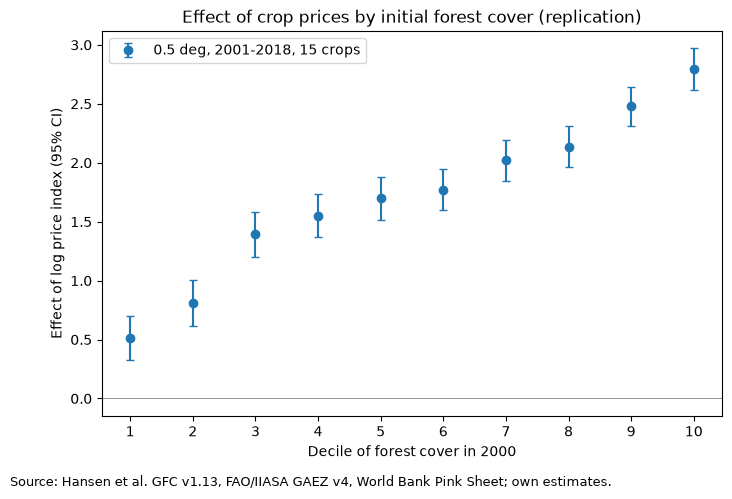

In [6]:
bt["decile"] = pd.qcut(bt.forest25_px, 10, labels=False) + 1
rep["decile"] = rep.block.map(bt.set_index("block").decile)
fit_rep2 = pf.feols("y ~ i(decile, lnP) | block + ct", rep, vcov={"CRV1": "block"})

def plot_deciles(fits, labels, title, fname):
    fig, ax = plt.subplots(figsize=(8, 5))
    for k, (fit, lab) in enumerate(zip(fits, labels)):
        t = fit.tidy()
        x = np.arange(1, 11) + (k - (len(fits) - 1) / 2) * 0.15
        ax.errorbar(x, t.Estimate, yerr=1.96 * t["Std. Error"], fmt="o", capsize=3, label=lab)
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("Decile of forest cover in 2000")
    ax.set_ylabel("Effect of log price index (95% CI)")
    ax.set_title(title)
    ax.legend()
    fig.text(0.01, -0.03, SOURCE, fontsize=9)
    fig.savefig(f"../figures/{fname}", dpi=200, bbox_inches="tight")
    plt.show()

plot_deciles([fit_rep2], ["0.5 deg, 2001-2018, 15 crops"], "Effect of crop prices by initial forest cover (replication)",
             "replication_deciles.png")

## 4. Finer: 9 km cells, 2001-2018, 15 crops

Same period and crops as the replication. SE clustered by 0.5 degree block (neighbouring 9 km cells are
strongly correlated); clustering by cell shown for comparison.

In [7]:
fine = to_long(cells, "cell_id", "loss25_", log_index(cells, CROPS_15, YEARS_R), YEARS_R, extra=("block",))
fit_fine = pf.feols("y ~ lnP | cell_id + ct", fine, vcov={"CRV1": "block"}, copy_data=False)
res.append(show(fit_fine, "9 km, 2001-2018, 15 crops (cluster 0.5 deg)"))
se_cell = pf.feols("y ~ lnP | cell_id + ct", fine, vcov={"CRV1": "cell_id"}, copy_data=False, lean=True)
res.append(show(se_cell, "same, SE clustered by 9 km cell"))
pd.concat(res[-2:])

,model,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%,N
Coefficient,,,,,,,,
lnP,"9 km, 2001-2018, 15 crops (cluster 0.5 deg)",1.070753,0.044427,24.101475,0.0,0.983671,1.157834,8795898
lnP,"same, SE clustered by 9 km cell",1.070753,0.015010,71.334612,0.0,1.041333,1.100172,8795898


## 5. Longer: 9 km cells, 2001-2025, 13 crops

Main specification of our article. Then: does the effect differ after 2018?

In [8]:
del fine
main = to_long(cells, "cell_id", "loss25_", log_index(cells, CROPS_13, YEARS), YEARS, extra=("block",))
main["post2018"] = (main.year > 2018).astype(int)
fit_main = pf.feols("y ~ lnP | cell_id + ct", main, vcov={"CRV1": "block"}, copy_data=False)
res.append(show(fit_main, "MAIN: 9 km, 2001-2025, 13 crops"))
fit_post = pf.feols("y ~ lnP + lnP:post2018 | cell_id + ct", main, vcov={"CRV1": "block"}, copy_data=False, lean=True)
res.append(show(fit_post, "9 km, 2001-2025: extra effect after 2018", keep="lnP:post2018"))
pd.concat(res[-2:])

,model,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%,N
Coefficient,,,,,,,,
lnP,"MAIN: 9 km, 2001-2025, 13 crops",0.963573,0.034026,28.318627,0.000000e+00,0.896878,1.030268,12183400
lnP:post2018,"9 km, 2001-2025: extra effect after 2018",0.311869,0.045499,6.854372,7.416734e-12,0.222685,0.401052,12183400


In [9]:
# Same 13 crops and period at 0.5 degree, to separate the effect of resolution from the effect of period
fit_b13 = pf.feols("y ~ lnP | block + ct",
                   (rep13 := to_long(bt, "block", "loss25_", log_index(bt, CROPS_13, YEARS), YEARS, extra=("lat", "lon"))),
                   vcov={"CRV1": "block"}, lean=True)
res.append(show(fit_b13, "0.5 deg, 2001-2025, 13 crops"))
res[-1]

,model,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%,N
Coefficient,,,,,,,,
lnP,"0.5 deg, 2001-2025, 13 crops",1.662473,0.05858,28.379469,0.0,1.547648,1.777299,333075


## 6. Contribution of crop prices to deforestation

As Berman et al. (footnote 10): predicted deforestation with observed prices vs prices fixed at their
2001 level, using the decile model. Predictions are transformed back from asinh with sinh. As in the paper
("the rise in crop prices was responsible for 35% of predicted global forest loss"), the contribution is the
share of predicted deforestation due to price changes: (observed - counterfactual) / observed.

Replication: 0.5 deg, 2001-2018, 15 crops: crop price changes since 2001 are responsible for 56% of predicted deforestation (deforestation 127% higher than with prices fixed at their 2001 level)


MAIN: 9 km, 2001-2025, 13 crops: crop price changes since 2001 are responsible for 44% of predicted deforestation (deforestation 77% higher than with prices fixed at their 2001 level)
Berman et al. (2023): 35% of predicted forest loss, 2001-2018


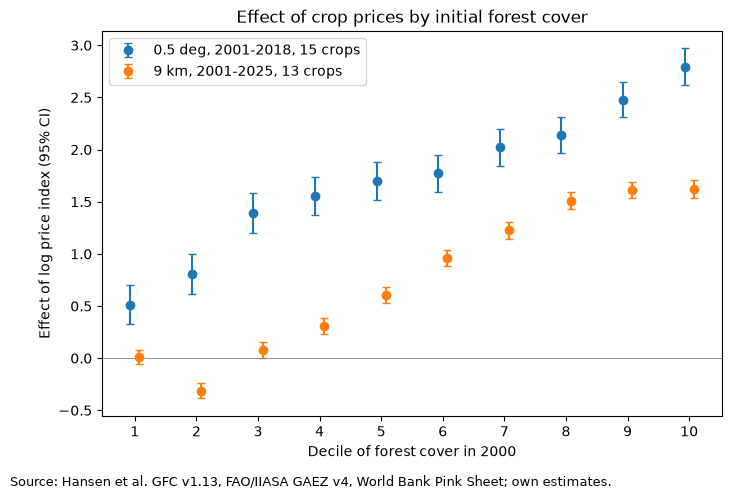

In [10]:
cell_dec = pd.qcut(cells.forest25_px, 10, labels=False) + 1
main["decile"] = np.repeat(cell_dec.to_numpy(), len(YEARS))[panel_pos(main)]
fit_main2 = pf.feols("y ~ i(decile, lnP) | cell_id + ct", main, vcov={"CRV1": "block"}, copy_data=False)
def price_contribution(fit, d, unit):
    """Share of predicted deforestation due to price changes since the first year (Berman et al., fn. 10).
    d must be sorted by unit and year, with the rows used by fit (nothing dropped)."""
    pred = fit.predict()
    assert len(pred) == len(d), "some observations were dropped by the estimation"
    lnP_first = d.groupby(unit).lnP.transform("first").to_numpy()      # first year = 2001
    shift = fit.coef().to_numpy()[d.decile.to_numpy() - 1] * (d.lnP.to_numpy() - lnP_first)
    obs, cf = np.sinh(pred).sum(), np.sinh(pred - shift).sum()
    return (obs - cf) / obs, (obs - cf) / cf

for name, fit, d, unit in [("Replication: 0.5 deg, 2001-2018, 15 crops", fit_rep2, rep, "block"),
                           ("MAIN: 9 km, 2001-2025, 13 crops", fit_main2, main, "cell_id")]:
    share, rise = price_contribution(fit, d, unit)
    print(f"{name}: crop price changes since 2001 are responsible for {share:.0%} of predicted deforestation "
          f"(deforestation {rise:.0%} higher than with prices fixed at their 2001 level)")
print("Berman et al. (2023): 35% of predicted forest loss, 2001-2018")
plot_deciles([fit_rep2, fit_main2], ["0.5 deg, 2001-2018, 15 crops", "9 km, 2001-2025, 13 crops"],
             "Effect of crop prices by initial forest cover", "main_deciles.png")

## 7. Inference: how precise is beta?

Three ways to compute the standard error of the main coefficients, from the least to the most conservative
assumption about correlated errors, plus a permutation test.
- Cluster by 0.5 degree block (main, as Berman et al.).
- Cluster by country (62 clusters): any correlation within a country is allowed.
- Conley (500 and 1,000 km): correlation between all cells closer than the cutoff in the same year, and
  within a cell over time (Berman et al., Tables OA.13-OA.14). Computed at 0.5 degree only: at 9 km the
  number of cell pairs is too large.
- Permutation of prices across crops: all shocks come from a few world prices, so cells with a similar
  crop mix receive the same shocks wherever they are (Adao, Kolesar and Morales 2019). We shuffle the
  price series between crops, re-estimate beta, and compare the true beta with this distribution.

In [11]:
from scipy.spatial import cKDTree

def demean(v, groups, n_iter=500, tol=1e-9):
    """Remove several sets of fixed effects by alternating projections."""
    v = v.astype(float).copy()
    for _ in range(n_iter):
        old = v.copy()
        for g in groups:
            v -= pd.Series(v).groupby(g).transform("mean").to_numpy()
        if np.abs(v - old).max() < tol:
            break
    return v


def conley_se(d, unit, cutoff_km, x="lnP", y="y"):
    """Conley SE of y ~ x | unit + ct. Uniform kernel in space (same year, distance < cutoff)
    plus serial correlation within each unit over all years."""
    groups = [d[unit].to_numpy(), d["ct"].to_numpy()]
    xt, yt = demean(d[x].to_numpy(), groups), demean(d[y].to_numpy(), groups)
    b = (xt * yt).sum() / (xt ** 2).sum()
    score = xt * (yt - b * xt)
    u = d[[unit, "lat", "lon"]].drop_duplicates(unit).reset_index(drop=True)
    la, lo = np.radians(u.lat.to_numpy()), np.radians(u.lon.to_numpy())
    xyz = np.c_[np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]
    pairs = cKDTree(xyz).query_pairs(2 * np.sin(cutoff_km / 6371 / 2), output_type="ndarray")
    pos = pd.Series(np.arange(len(u)), index=u[unit])
    S = np.zeros((len(u), d.year.nunique()))
    np.add.at(S, (pos[d[unit]].to_numpy(), pd.Categorical(d.year).codes), score)
    spatial = (S ** 2).sum() + 2 * (S[pairs[:, 0]] * S[pairs[:, 1]]).sum()
    serial = (S.sum(axis=1) ** 2).sum() - (S ** 2).sum()
    return b, np.sqrt(spatial + serial) / (xt ** 2).sum()


def within(M, country):
    """Remove cell and country x year fixed effects from a balanced panel (cells x years).
    Cells are nested in countries, so one pass is exact: subtract the cell mean, then the
    country x year mean of what is left."""
    M = M - M.mean(axis=1, keepdims=True)
    G = np.zeros((country.max() + 1, M.shape[1]))
    np.add.at(G, country, M)
    return M - (G / np.bincount(country)[:, None])[country]


def permutation_test(units, crops, years, prefix="loss25_", n_perm=1000, seed=0):
    """True beta and betas after shuffling the price series across crops (same cells, same outcome)."""
    rng = np.random.default_rng(seed)
    S = units[crops].to_numpy(float)
    tot = S.sum(axis=1, keepdims=True)
    ok = tot[:, 0] > 0
    alpha = S[ok] / tot[ok]
    country = pd.Categorical(units.iso3[ok]).codes
    yt = within(np.arcsinh(units.loc[ok, [f"{prefix}{y}" for y in years]].to_numpy(float)), country)
    prices = P.loc[years, crops].to_numpy()
    beta = lambda pr: (lambda xt: (xt * yt).sum() / (xt ** 2).sum())(within(np.log(alpha @ pr.T), country))
    b0 = beta(prices)
    perm = np.array([beta(prices[:, rng.permutation(len(crops))]) for _ in range(n_perm)])
    return b0, perm

In [12]:
inf = []
specs = [("0.5 deg, 2001-2018, 15 crops (replication)", rep, bt, CROPS_15, YEARS_R),
         ("0.5 deg, 2001-2025, 13 crops", rep13, bt, CROPS_13, YEARS)]
for name, d, units, crops, years in specs:
    row = {"model": name}
    for label, vc in [("SE cluster 0.5 deg", {"CRV1": "block"}), ("SE cluster country", {"CRV1": "country"})]:
        fit = pf.feols("y ~ lnP | block + ct", d, vcov=vc, lean=True)
        row["beta"] = fit.coef().iloc[0]
        row[label] = fit.se().iloc[0]
    for km in (500, 1000):
        row[f"SE Conley {km} km"] = conley_se(d, "block", km)[1]
    inf.append(row)

# 9 km: block and country clusters (Conley is too heavy at 9 km: billions of cell pairs)
for name, d, crops, years in [("9 km, 2001-2018, 15 crops", None, CROPS_15, YEARS_R),
                              ("MAIN: 9 km, 2001-2025, 13 crops", main, CROPS_13, YEARS)]:
    if d is None:
        d = to_long(cells, "cell_id", "loss25_", log_index(cells, CROPS_15, YEARS_R), YEARS_R, extra=("block",))
    row = {"model": name}
    for label, vc in [("SE cluster 0.5 deg", {"CRV1": "block"}), ("SE cluster country", {"CRV1": "country"})]:
        fit = pf.feols("y ~ lnP | cell_id + ct", d, vcov=vc, copy_data=False, lean=True)
        row["beta"] = fit.coef().iloc[0]
        row[label] = fit.se().iloc[0]
    inf.append(row)
    del d
inference = pd.DataFrame(inf).set_index("model")
inference.round(4)

,beta,SE cluster 0.5 deg,SE cluster country,SE Conley 500 km,SE Conley 1000 km
model,,,,,
"0.5 deg, 2001-2018, 15 crops (replication)",1.9672,0.0796,0.2804,0.2093,0.2554
"0.5 deg, 2001-2025, 13 crops",1.6625,0.0586,0.2658,0.1413,0.1845
"9 km, 2001-2018, 15 crops",1.0708,0.0444,0.1637,NaN,NaN
"MAIN: 9 km, 2001-2025, 13 crops",0.9636,0.0340,0.1915,NaN,NaN


In [13]:
# Permutation test: 1,000 random reassignments of the price series across crops
perm_specs = [("0.5 deg, 2001-2018, 15 crops (replication)", bt, CROPS_15, YEARS_R),
              ("0.5 deg, 2001-2025, 13 crops", bt, CROPS_13, YEARS),
              ("9 km, 2001-2018, 15 crops", cells, CROPS_15, YEARS_R),
              ("MAIN: 9 km, 2001-2025, 13 crops", cells, CROPS_13, YEARS)]
perms = {}
for name, units, crops, years in perm_specs:
    t0 = time.time()
    b0, perm = permutation_test(units, crops, years)
    perms[name] = (b0, perm)
    inference.loc[name, "permutation p"] = (np.abs(perm) >= abs(b0)).mean()
    inference.loc[name, "permutation 95th pct |beta|"] = np.percentile(np.abs(perm), 95)
    print(f"{name}: beta {b0:.3f}, {time.time() - t0:.0f} s")
inference.round(4)

0.5 deg, 2001-2018, 15 crops (replication): beta 1.967, 4 s


0.5 deg, 2001-2025, 13 crops: beta 1.662, 5 s


9 km, 2001-2018, 15 crops: beta 1.071, 168 s


MAIN: 9 km, 2001-2025, 13 crops: beta 0.964, 248 s


,beta,SE cluster 0.5 deg,SE cluster country,SE Conley 500 km,SE Conley 1000 km,permutation p,permutation 95th pct |beta|
model,,,,,,,
"0.5 deg, 2001-2018, 15 crops (replication)",1.9672,0.0796,0.2804,0.2093,0.2554,0.103,2.1441
"0.5 deg, 2001-2025, 13 crops",1.6625,0.0586,0.2658,0.1413,0.1845,0.029,1.5767
"9 km, 2001-2018, 15 crops",1.0708,0.0444,0.1637,NaN,NaN,0.060,1.1187
"MAIN: 9 km, 2001-2025, 13 crops",0.9636,0.0340,0.1915,NaN,NaN,0.006,0.7384


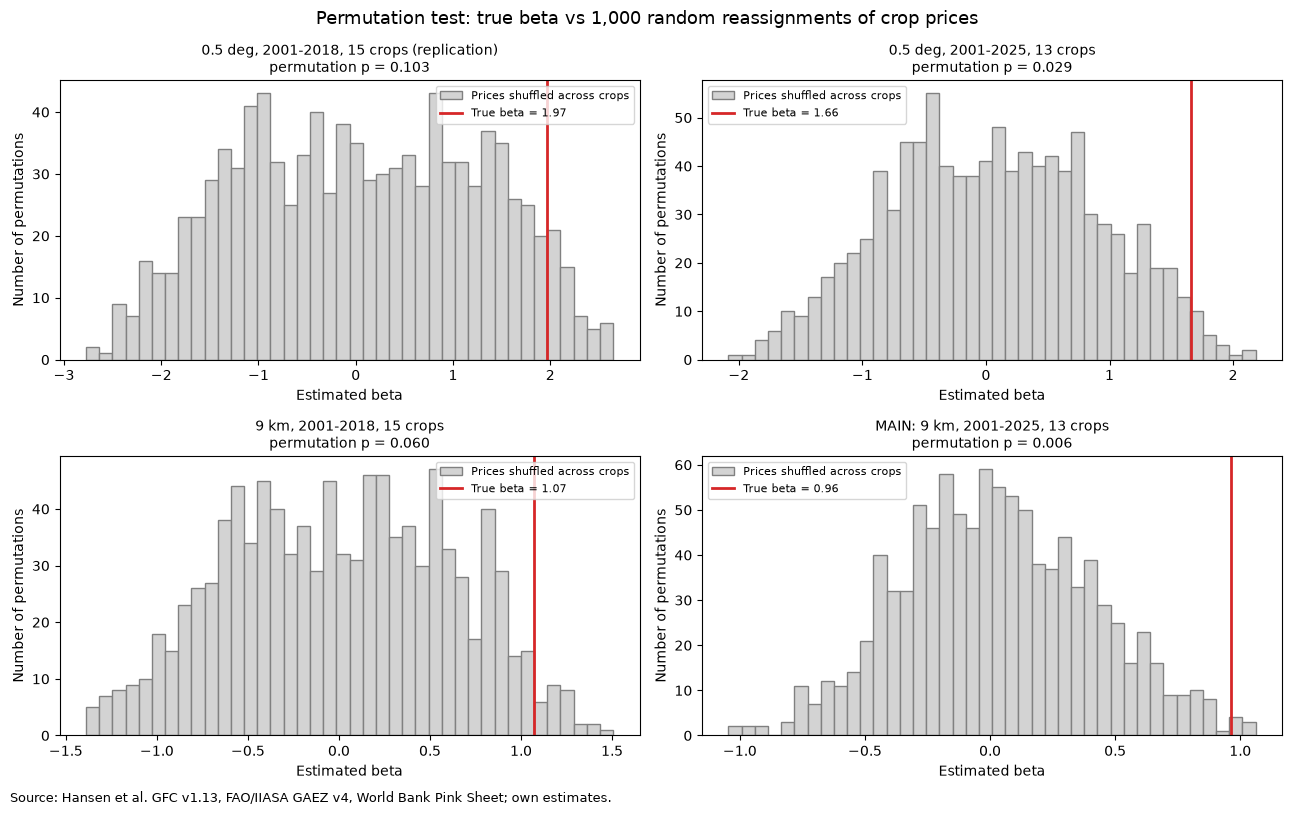

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (name, (b0, perm)) in zip(axes.flat, perms.items()):
    ax.hist(perm, bins=40, color="lightgrey", edgecolor="grey", label="Prices shuffled across crops")
    ax.axvline(b0, color="tab:red", lw=2, label=f"True beta = {b0:.2f}")
    ax.set_title(f"{name}\npermutation p = {(np.abs(perm) >= abs(b0)).mean():.3f}", fontsize=10)
    ax.set_xlabel("Estimated beta")
    ax.set_ylabel("Number of permutations")
    ax.legend(fontsize=8)
fig.suptitle("Permutation test: true beta vs 1,000 random reassignments of crop prices", fontsize=13)
fig.text(0.01, -0.01, SOURCE, fontsize=9)
fig.tight_layout()
fig.savefig("../figures/permutation_test.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Robustness

In [15]:
rob = []
# Canopy threshold 50 percent
m50 = to_long(cells, "cell_id", "loss50_", log_index(cells, CROPS_13, YEARS), YEARS, extra=("block",))
rob.append(show(pf.feols("y ~ lnP | cell_id + ct", m50, vcov={"CRV1": "block"}, copy_data=False, lean=True),
                "Canopy 50%"))
del m50
# Lagged price index
main = main.sort_values(["cell_id", "year"])
for k in (1, 2):
    main[f"lnP_l{k}"] = main.groupby("cell_id").lnP.shift(k)
    rob.append(show(pf.feols(f"y ~ lnP_l{k} | cell_id + ct", main.dropna(subset=[f"lnP_l{k}"]),
                             vcov={"CRV1": "block"}, lean=True), f"Price index t-{k}", keep=f"lnP_l{k}"))
# Average suitability x year (Berman et al., Figure OA.12)
main["avg_suit"] = np.repeat(cells[CROPS_13].mean(axis=1).to_numpy(), len(YEARS))[panel_pos(main)]
rob.append(show(pf.feols("y ~ lnP + i(year, avg_suit) | cell_id + ct", main, vcov={"CRV1": "block"},
                         copy_data=False, lean=True), "Average suitability x year"))
# Tropics band only
rob.append(show(pf.feols("y ~ lnP | cell_id + ct", main[main.cell_id.isin(cells.cell_id[cells.in_tropics == 1])],
                         vcov={"CRV1": "block"}, lean=True), "Tropics band only"))
pd.concat(rob)

/var/folders/g_/n5j5vrsd2sg8l7htfcc6jvb40000gn/T/ipykernel_62476/163673690.py:15: UserWarning: 
            1 variables dropped due to multicollinearity.
            The following variables are dropped: ['year::2025:avg_suit'].
            
  rob.append(show(pf.feols("y ~ lnP + i(year, avg_suit) | cell_id + ct", main, vcov={"CRV1": "block"},


,model,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%,N
Coefficient,,,,,,,,
lnP,Canopy 50%,0.946423,0.031638,29.914161,0.0,0.884409,1.008437,12183400
lnP_l1,Price index t-1,0.689657,0.033429,20.630805,0.0,0.624134,0.755181,11696064
lnP_l2,Price index t-2,0.806130,0.037326,21.597223,0.0,0.732968,0.879292,11208728
lnP,Average suitability x year,1.190812,0.035610,33.440706,0.0,1.121013,1.260611,12183400
lnP,Tropics band only,1.074973,0.042682,25.185916,0.0,0.991312,1.158635,9959850


In [16]:
# PPML on pixel counts: coefficients are elasticities, comparable across resolutions
# Same period, two resolutions: the 2 x 2 table separates the effect of resolution from the effect of period
fine = to_long(cells, "cell_id", "loss25_", log_index(cells, CROPS_15, YEARS_R), YEARS_R, extra=("block",))
for name, d, fe in [("PPML replication: 0.5 deg, 2001-2018, 15 crops", rep, "block"),
                    ("PPML 9 km, 2001-2018, 15 crops", fine, "cell_id"),
                    ("PPML 0.5 deg, 2001-2025, 13 crops", rep13, "block"),
                    ("PPML main: 9 km, 2001-2025, 13 crops", main, "cell_id")]:
    fit = pf.fepois(f"loss ~ lnP | {fe} + ct", d, vcov={"CRV1": "block"}, lean=True)
    rob.append(show(fit, name))
del fine
pd.concat(rob[-4:])

/var/folders/g_/n5j5vrsd2sg8l7htfcc6jvb40000gn/T/ipykernel_62476/171502505.py:8: UserWarning: 4752 observations removed because of separation.
  fit = pf.fepois(f"loss ~ lnP | {fe} + ct", d, vcov={"CRV1": "block"}, lean=True)


/var/folders/g_/n5j5vrsd2sg8l7htfcc6jvb40000gn/T/ipykernel_62476/171502505.py:8: UserWarning: 597294 observations removed because of separation.
  fit = pf.fepois(f"loss ~ lnP | {fe} + ct", d, vcov={"CRV1": "block"}, lean=True)


/var/folders/g_/n5j5vrsd2sg8l7htfcc6jvb40000gn/T/ipykernel_62476/171502505.py:8: UserWarning: 6275 observations removed because of separation.
  fit = pf.fepois(f"loss ~ lnP | {fe} + ct", d, vcov={"CRV1": "block"}, lean=True)


/var/folders/g_/n5j5vrsd2sg8l7htfcc6jvb40000gn/T/ipykernel_62476/171502505.py:8: UserWarning: 765525 observations removed because of separation.
  fit = pf.fepois(f"loss ~ lnP | {fe} + ct", d, vcov={"CRV1": "block"}, lean=True)


,model,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%,N
Coefficient,,,,,,,,
lnP,"PPML replication: 0.5 deg, 2001-2018, 15 crops",1.497140,0.136534,10.965305,0.0,1.229538,1.764742,235098
lnP,"PPML 9 km, 2001-2018, 15 crops",1.064506,0.112545,9.458457,0.0,0.843921,1.285091,8198604
lnP,"PPML 0.5 deg, 2001-2025, 13 crops",1.066381,0.096597,11.039477,0.0,0.877054,1.255708,326800
lnP,"PPML main: 9 km, 2001-2025, 13 crops",0.842609,0.076622,10.996957,0.0,0.692432,0.992785,11417875


## 9. Period or crop set?

Between the 2001-2018 models (15 crops) and the 2001-2025 models (13 crops) two things change at once.
We estimate 2001-2018 with the 13 crops, at both resolutions, to separate the two.

In [17]:
fine13 = to_long(cells, "cell_id", "loss25_", log_index(cells, CROPS_13, YEARS_R), YEARS_R, extra=("block",))
fit_fine13 = pf.feols("y ~ lnP | cell_id + ct", fine13, vcov={"CRV1": "block"}, copy_data=False, lean=True)
res.append(show(fit_fine13, "9 km, 2001-2018, 13 crops"))
del fine13
rep_13 = to_long(bt, "block", "loss25_", log_index(bt, CROPS_13, YEARS_R), YEARS_R, extra=("lat", "lon"))
fit_rep13 = pf.feols("y ~ lnP | block + ct", rep_13, vcov={"CRV1": "block"}, lean=True)
res.append(show(fit_rep13, "0.5 deg, 2001-2018, 13 crops"))

# Permutation test for the two new models (same procedure as section 7)
for name, units in [("0.5 deg, 2001-2018, 13 crops", bt), ("9 km, 2001-2018, 13 crops", cells)]:
    b0, perm = permutation_test(units, CROPS_13, YEARS_R)
    inference.loc[name, ["beta", "permutation p", "permutation 95th pct |beta|"]] = \
        [b0, (np.abs(perm) >= abs(b0)).mean(), np.percentile(np.abs(perm), 95)]

# Beta by resolution, period and crop set (OLS, asinh)
beta = lambda f: f.coef().iloc[0]
decomp = pd.DataFrame({
    "2001-2018, 15 crops": [beta(fit_rep), beta(fit_fine)],
    "2001-2018, 13 crops": [beta(fit_rep13), beta(fit_fine13)],
    "2001-2025, 13 crops": [beta(fit_b13), beta(fit_main)],
}, index=["0.5 deg", "9 km"])
display(decomp.round(3))
inference.loc[[i for i in inference.index if "2001-2018" in i], ["beta", "permutation p"]].round(3)

,"2001-2018, 15 crops","2001-2018, 13 crops","2001-2025, 13 crops"
0.5 deg,1.967,2.068,1.662
9 km,1.071,1.120,0.964


,beta,permutation p
model,,
"0.5 deg, 2001-2018, 15 crops (replication)",1.967,0.103
"9 km, 2001-2018, 15 crops",1.071,0.060
"0.5 deg, 2001-2018, 13 crops",2.068,0.022
"9 km, 2001-2018, 13 crops",1.120,0.004


## 10. Neighbouring cells: local spillovers or regional effect?

The elasticity is smaller at 9 km than at 0.5 degree. We add the price index of the land around each cell
(all land cells with a suitable crop, forest or not), in rings of grid cells: ring 1 (adjacent, about
9-18 km), ring 2 (2-3 cells, up to about 30 km), ring 3 (4-6 cells, up to about 55 km) and a far ring
(7-12 cells, about 60-110 km) as a placebo for local spillovers. Main specification (9 km, 2001-2025,
13 crops). The neighbour indices are strongly collinear with the own index: only the total effect (sum of
the coefficients) is precise.

In [18]:
from scipy.ndimage import convolve

def neighbour_indices(crops, years, rings):
    """Log price index of the land around each cell, for each ring (min, max) of grid cells."""
    r0, r1 = cells.row.min() - 12, cells.row.max() + 13          # rows needed for the largest ring
    S = []
    for crop in crops:
        layers = []
        for c in GAEZ_CODES[crop]:
            with rasterio.open(BASE + f"raw/gaez/sxHr_{c}.tif") as src:
                layers.append(np.clip(src.read(1)[r0:r1].astype(np.float32), 0, None) / 10000)
        S.append(np.max(layers, axis=0))
    S = np.stack(S, -1)
    tot = S.sum(-1)
    land = tot > 0                                                # cells with at least one suitable crop
    alpha = np.where(land[..., None], S / np.where(land, tot, 1)[..., None], 0)
    idx = (alpha @ P.loc[years, crops].to_numpy().T).astype(np.float32)   # rows x cols x years
    rr, cc = cells.row.to_numpy() - r0, cells.col.to_numpy()
    out = {}
    for name, (a, b) in rings.items():
        k = np.ones((2 * b + 1, 2 * b + 1))
        k[b - a + 1:b + a, b - a + 1:b + a] = 0                   # remove the inner square (and the cell)
        n = convolve(land.astype(float), k, mode="wrap")[rr, cc]
        s = np.stack([convolve(idx[..., t], k, mode="wrap")[rr, cc] for t in range(len(years))], axis=1)
        out[name] = np.log(np.where(n[:, None] > 0, s / np.maximum(n, 1)[:, None], np.nan)).astype(np.float32)
    return out

RINGS = {"ring1": (1, 1), "ring2": (2, 3), "ring3": (4, 6), "far": (7, 12)}
nbr = neighbour_indices(CROPS_13, YEARS, RINGS)
for name, v in nbr.items():
    main[name] = v.ravel()[panel_pos(main)]
sp = main.dropna(subset=list(RINGS))

rows = []
for label, rhs in [("Own cell only", "lnP"), ("+ ring 1", "lnP + ring1"),
                   ("+ rings 1-3", "lnP + ring1 + ring2 + ring3"),
                   ("+ rings 1-3 + far ring", "lnP + ring1 + ring2 + ring3 + far"),
                   ("Own cell + far ring", "lnP + far")]:
    fit = pf.feols(f"y ~ {rhs} | cell_id + ct", sp, vcov={"CRV1": "block"}, copy_data=False, lean=True)
    b, V = fit.coef(), fit._vcov
    row = {"model": label, **{f"{k} (beta)": b.get(k, np.nan) for k in ["lnP"] + list(RINGS)}}
    row["total"], row["total SE"] = b.sum(), np.sqrt(V.sum())
    rows.append(row)
spill = pd.DataFrame(rows).set_index("model")
r2 = pf.feols("lnP ~ ring1 + ring2 + ring3 + far | cell_id + ct", sp, copy_data=False, lean=True)._r2_within
print(f"Share of the within variation of the own index explained by the neighbour indices: {r2:.2f}")
spill.round(3)

Share of the within variation of the own index explained by the neighbour indices: 0.91


,lnP (beta),ring1 (beta),ring2 (beta),ring3 (beta),far (beta),total,total SE
model,,,,,,,
Own cell only,0.965,NaN,NaN,NaN,NaN,0.965,0.034
+ ring 1,0.079,0.991,NaN,NaN,NaN,1.070,0.038
+ rings 1-3,0.173,0.042,-0.418,1.493,NaN,1.290,0.044
+ rings 1-3 + far ring,0.178,-0.004,-0.024,-0.020,1.298,1.428,0.048
Own cell + far ring,0.160,NaN,NaN,NaN,1.267,1.427,0.048


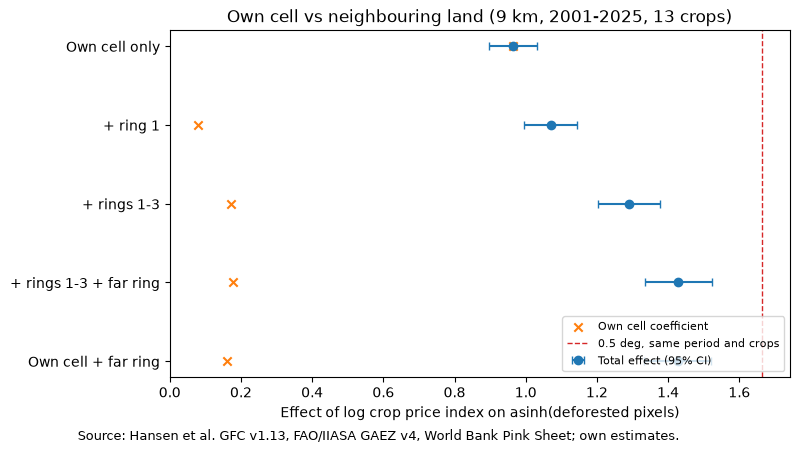

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(spill))[::-1]
ax.errorbar(spill.total, y, xerr=1.96 * spill["total SE"], fmt="o", capsize=3, label="Total effect (95% CI)")
ax.scatter(spill["lnP (beta)"], y, marker="x", color="tab:orange", label="Own cell coefficient")
ax.axvline(fit_b13.coef().iloc[0], color="tab:red", ls="--", lw=1, label="0.5 deg, same period and crops")
ax.set_yticks(y)
ax.set_yticklabels(spill.index)
ax.set_xlabel("Effect of log crop price index on asinh(deforested pixels)")
ax.set_title("Own cell vs neighbouring land (9 km, 2001-2025, 13 crops)")
ax.legend(fontsize=8, loc="lower right")
fig.text(0.01, -0.03, SOURCE, fontsize=9)
fig.savefig("../figures/neighbour_rings.png", dpi=200, bbox_inches="tight")
plt.show()
del sp, nbr

## 11. Do protected areas dampen the effect of crop prices?

Country x year fixed effects absorb national policies, so we cannot estimate their effect on the level of
deforestation. We can test whether cells inside protected areas respond less to the same price shock:
interaction of the log price index with the share of the cell protected before 2001 (WDPA, November 2026,
`scripts/build_protected_areas.py`). Protected areas sit in cells with more forest, where the price effect
is larger (section 6), so we also control for deciles of forest cover x log price index. The location of
protected areas is not random: these interactions describe heterogeneity, not a causal effect of protection.

In [20]:
pa = pd.read_csv(BASE + "processed/grid_protected.csv.gz").set_index("cell_id").reindex(cells.cell_id)
pa["pa_after"] = (pa.pa2025 - pa.pa2000 - pa.pa_noyear).clip(lower=0)      # protected during 2001-2025
pos = panel_pos(main) // len(YEARS)                                          # row of each observation in cells
for c in ["pa2000", "pa2000_strict", "pa_after"]:
    main[c] = pa[c].to_numpy(np.float32)[pos]
main["pa_bin"] = (main.pa2000 >= 0.5).astype(np.float32)
print(f"Cells protected before 2001: {(pa.pa2000 > 0).mean():.1%} partly, {(pa.pa2000 >= 0.5).mean():.1%} for at least half")
rate = cells[[f"loss25_{y}" for y in YEARS]].sum(axis=1) / cells.forest25_px
print(f"Forest lost 2001-2025: {rate[pa.pa2000.to_numpy() >= 0.5].mean():.1%} in protected cells, "
      f"{rate[pa.pa2000.to_numpy() < 0.5].mean():.1%} in the others")

pa_specs = [("Share protected by 2000", "lnP + lnP:pa2000", "lnP:pa2000"),
            ("Protected by 2000 (at least 50% of the cell)", "lnP + lnP:pa_bin", "lnP:pa_bin"),
            ("Share strictly protected (IUCN I-IV) by 2000", "lnP + lnP:pa2000_strict", "lnP:pa2000_strict"),
            ("Share protected by 2000, forest deciles x lnP", "i(decile, lnP) + lnP:pa2000", "lnP:pa2000"),
            ("Share strictly protected, forest deciles x lnP", "i(decile, lnP) + lnP:pa2000_strict", "lnP:pa2000_strict"),
            ("Share protected 2001-2025 (selection check)", "lnP + lnP:pa2000 + lnP:pa_after", "lnP:pa_after")]
pa_res = []
for name, rhs, keep in pa_specs:
    fit = pf.feols(f"y ~ {rhs} | cell_id + ct", main, vcov={"CRV1": "block"}, copy_data=False, lean=True)
    pa_res.append(show(fit, name, keep=keep))
pa_res = pd.concat(pa_res)
pa_res[["model", "Estimate", "Std. Error", "Pr(>|t|)", "2.5%", "97.5%"]].round(3)

Cells protected before 2001: 19.6% partly, 10.9% for at least half
Forest lost 2001-2025: 7.3% in protected cells, 14.2% in the others


,model,Estimate,Std. Error,Pr(>|t|),2.5%,97.5%
Coefficient,,,,,,
lnP:pa2000,Share protected by 2000,0.059,0.042,0.157,-0.023,0.142
lnP:pa_bin,Protected by 2000 (at least 50% of the cell),0.050,0.036,0.168,-0.021,0.122
lnP:pa2000_strict,Share strictly protected (IUCN I-IV) by 2000,-0.328,0.060,0.000,-0.446,-0.210
lnP:pa2000,"Share protected by 2000, forest deciles x lnP",-0.296,0.041,0.000,-0.376,-0.216
lnP:pa2000_strict,"Share strictly protected, forest deciles x lnP",-0.631,0.058,0.000,-0.744,-0.517
lnP:pa_after,Share protected 2001-2025 (selection check),0.262,0.040,0.000,0.183,0.341


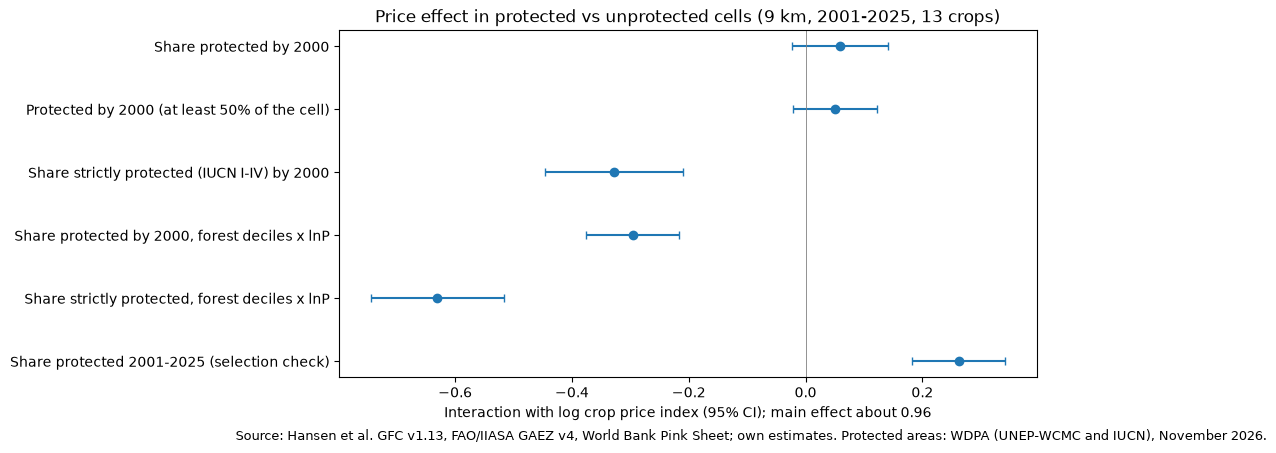

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(pa_res))[::-1]
ax.errorbar(pa_res.Estimate, y, xerr=1.96 * pa_res["Std. Error"], fmt="o", capsize=3)
ax.axvline(0, color="grey", lw=0.6)
ax.set_yticks(y)
ax.set_yticklabels(pa_res.model)
ax.set_xlabel("Interaction with log crop price index (95% CI); main effect about 0.96")
ax.set_title("Price effect in protected vs unprotected cells (9 km, 2001-2025, 13 crops)")
fig.text(0.01, -0.03, SOURCE + " Protected areas: WDPA (UNEP-WCMC and IUCN), November 2026.", fontsize=9)
fig.savefig("../figures/protected_areas.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Why is our replication beta higher than Berman et al.'s?

Our replication gives 1.97, Berman et al. 1.27. We use their own replication files (Zenodo 7044013) to find
out why. The comparison is run once locally (`scripts/compare_berman.py`, their Stata files are not in the
repository); the notebook reads its results. All models: asinh(lost pixels) on the log price index, cell and
country x year fixed effects, SE clustered by cell, 0.5 degree cells, 2001-2018, 15 crops, on the 11,856
cells that both samples share (96% of their cells).

In [ ]:
comp = pd.read_csv(BASE + "processed/berman_comparison.csv")
main_rows = comp[comp["sample"] != "common cells, one price swapped"]
main_rows[["sample", "model", "beta", "se", "N"]].round(3)

In [ ]:
# Our index with ONE price series replaced by Berman et al.'s: which crops matter?
one = comp[comp["sample"] == "common cells, one price swapped"].copy()
one["crop"] = one.model.str.replace("Our index, Berman et al. price for ", "")
ours = comp.loc[comp.model == "Our outcome, our index", "beta"].iloc[0]
one.assign(change=one.beta - ours).sort_values("change")[["crop", "beta", "change"]].round(3).T

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
r = main_rows.iloc[::-1]
y = np.arange(len(r))
ax.errorbar(r.beta, y, xerr=1.96 * r.se, fmt="o", capsize=3)
ax.axvline(BERMAN_BETA, color="tab:red", ls="--", lw=1, label="Berman et al. (2023): 1.27")
ax.set_yticks(y)
ax.set_yticklabels(r.model, fontsize=9)
ax.set_xlabel("Effect of log crop price index (95% CI)")
ax.set_title("Swapping outcome, suitability and prices (0.5 deg, 2001-2018)")
ax.legend(loc="lower right", fontsize=8)

bp = pd.read_csv(BASE + "processed/berman_prices.csv").set_index("year")
ax = axes[1]
for crop, color in [("banana", "tab:olive"), ("sugarcane", "tab:purple")]:
    ax.plot(bp.index, bp[f"{crop}_ours"], color=color, label=f"{crop.replace('cane', '')}, our series (Pink Sheet)")
    ax.plot(bp.index, bp[f"{crop}_Berman et al."], color=color, ls="--", label=f"{crop.replace('cane', '')}, Berman et al.")
ax.set_xlabel("Year")
ax.set_xticks(range(2002, 2019, 4))
ax.set_ylabel("Real price index (2000 = 100)")
ax.set_title("The two price series that differ most")
ax.legend(fontsize=8)
fig.text(0.01, -0.03, SOURCE + " Berman et al. (2023) replication files, Zenodo 7044013.", fontsize=9)
fig.tight_layout()
fig.savefig("../figures/berman_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

> To write (Andrew): what the comparison shows. Points to cover: with their data and code we get exactly
> their 1.27; on the shared cells, the deforestation and forest data are the same (their outcome or ours
> gives the same beta); the whole gap comes from the price index: two price series (banana, sugar: their
> sugar is not the world price) and the GAEZ version (v3 vs v4); part of the gap remains unexplained (their
> index rebuilt from their own files gives 1.75). Sign and significance hold in every combination.

## 13. Summary

In [22]:
summary = pd.concat(res + rob)[["model", "Estimate", "Std. Error", "Pr(>|t|)", "2.5%", "97.5%", "N"]]
summary.round(3).reset_index(drop=True)

,model,Estimate,Std. Error,Pr(>|t|),2.5%,97.5%,N
0,"Replication: 0.5 deg, 2001-2018, 15 crops",1.967,0.080,0.0,1.811,2.123,239850
1,"9 km, 2001-2018, 15 crops (cluster 0.5 deg)",1.071,0.044,0.0,0.984,1.158,8795898
2,"same, SE clustered by 9 km cell",1.071,0.015,0.0,1.041,1.100,8795898
3,"MAIN: 9 km, 2001-2025, 13 crops",0.964,0.034,0.0,0.897,1.030,12183400
4,"9 km, 2001-2025: extra effect after 2018",0.312,0.045,0.0,0.223,0.401,12183400
5,"0.5 deg, 2001-2025, 13 crops",1.662,0.059,0.0,1.548,1.777,333075
6,"9 km, 2001-2018, 13 crops",1.120,0.042,0.0,1.037,1.203,8772048
7,"0.5 deg, 2001-2018, 13 crops",2.068,0.081,0.0,1.909,2.226,239814
8,Canopy 50%,0.946,0.032,0.0,0.884,1.008,12183400
9,Price index t-1,0.690,0.033,0.0,0.624,0.755,11696064


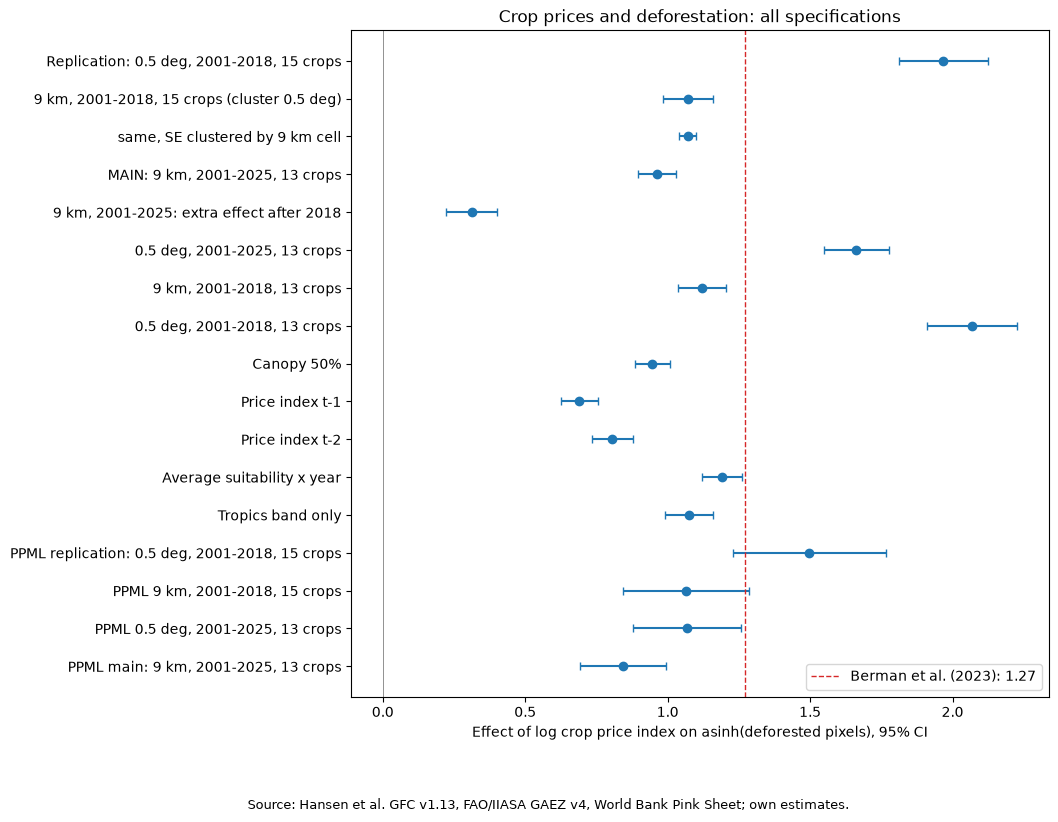

In [23]:
fig, ax = plt.subplots(figsize=(9, 0.45 * len(summary) + 1))
y = np.arange(len(summary))[::-1]
ax.errorbar(summary.Estimate, y, xerr=1.96 * summary["Std. Error"], fmt="o", capsize=3)
ax.axvline(0, color="grey", lw=0.6)
ax.axvline(BERMAN_BETA, color="tab:red", ls="--", lw=1, label="Berman et al. (2023): 1.27")
ax.set_yticks(y)
ax.set_yticklabels(summary.model)
ax.set_xlabel("Effect of log crop price index on asinh(deforested pixels), 95% CI")
ax.set_title("Crop prices and deforestation: all specifications")
ax.legend(loc="lower right")
fig.text(0.01, -0.02, SOURCE, fontsize=9)
fig.savefig("../figures/grid_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()